In [2]:
from __future__ import annotations  # 启用未来功能，允许类型注解

import argparse # 解析命令行参数
import json # 用于读取和保存json数据
import os # 用于和操作系统进行交互
from pathlib import Path # 路径处理
import sys # 和python运行环境相关的功能
import time # 时间相关的功能

from AI.strict_paper_simulation.strict_full_orbit_simulation import U_RESONANCE, U_PARALLEL_MIN, N_PARTICLES

cache = Path("/tmp/simulation_particle_cache") # 设置缓存目录(这里只是一个路径对象)
#参数1:如果上层目录不存在，也一并创建。 参数2:如果文件夹存在，不会报错。
cache.mkdir(parents=True, exist_ok=True) # 创建真正的缓存文件夹

# 这个里面存的是系统的环境变量。只有环境变量还没有设置的时候才设置它，不覆盖用户原来的设置。
# cache = Path("/tmp/strict_paper_simulation_cache")
# 所以得到的路径是 /tmp/strict_paper_simulation_cache/matplotlib
# MPLCONFIGDIR 是 Matplotlib 使用的环境变量
# 告诉 Matplotlib：“你的配置文件和缓存放到这个地方。”
os.environ.setdefault("MPLCONFIGDIR", str(cache / "matplotlib"))
# 其他缓存
os.environ.setdefault("XDG_CACHE_HOME", str(cache / "xdg_cache"))

# 设置完matplot环境变量之后，再导包 matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display # Jupyter/IPython 提供的东西。可以直接在 Notebook 里面显示图片。

# cwd = current working directory 当前工作目录
# .parent 上一级目录
# resolve() 方法返回路径的绝对路径
cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "AI_hoshino", cwd.parent / "AI_hoshino",]

"""
生成器表达式，逻辑类似：
for p in candidates:
    if p.exists() and p.name == "AI_hoshino":
        ...

next(...) 返回第一个符合条件的路径；
如果没找到，则返回 None。
"""
PROJECT_ROOT = next((p for p in candidates if p.exists() and p.name == "AI_hoshino"), None,)
if PROJECT_ROOT is None :
    raise RuntimeError(f"没有找到 AI_hoshino 项目目录。当前工作目录是：{cwd}")

# 这里目前只是“定义路径”，并没有创建这些目录。后面还需要类似：DATA_DIR.mkdir(parents=True, exist_ok=True)来创建目录
ROOT = PROJECT_ROOT / "notebook_outputs" / "simulation_particle" # 项目根目录
DATA_DIR = ROOT / "data" # 数值模拟结果
FIGURE_DIR = ROOT / "figures" # 生成的图片
REPORT_DIR = ROOT / "reports" # 模拟报告或检查结果

print("项目根目录：", PROJECT_ROOT)

项目根目录： /Users/zerek/Desktop/plasma physics/AI_hoshino


In [3]:
W = 0.2
K = 0.2
BW = 1.024e-4

U_RESONANCE = (W + 1.0) / K

u_perp = 1.0  # perpendicular component of velocity
u_trap = 2.0 * np.sqrt(u_perp * BW / K)

print("u_R =", U_RESONANCE)
print("u_t =", u_trap) # 当垂直速度为1.0时， u_t = 0.04525483399593904
print(
    "trapping range =",
    U_RESONANCE - u_trap,
    U_RESONANCE + u_trap,
) # 当垂直速度为1.0时，对应的平行速度的捕捉范围

u_R = 5.999999999999999
u_t = 0.04525483399593904
trapping range = 5.95474516600406 6.045254833995938


In [4]:
# Test-particle 平行速度的取值范围
U_PARALLEL_MIN = 5.8
U_PARALLEL_MAX = 6.2

# Test-particle 垂直速度的取值范围
U_PERP_MIN = 0.1
U_PERP_MAX = 1.0

# 式7中的PSI的取值范围。这个角度的初值会影响trapping区域的宽度
PSI_MIN = -np.pi
PSI_MAX = np.pi

# Number of test particles
N_PARTICLES = 720

# Random number generator
# 固定随机种子后，每次运行都会得到相同的一组随机粒子
rng = np.random.default_rng(42)

# Initial parallel velocity
# 举例：rng.uniform(0, 1, 5) 生成5个在0到1之间的随机数，uniform是均匀采样
u_parallel0 = rng.uniform(U_PARALLEL_MIN, U_PARALLEL_MAX, N_PARTICLES)

# Initial perpendicular velocity
u_perp0 = rng.uniform(U_PERP_MIN, U_PERP_MAX, N_PARTICLES)

# Initial phase difference
psi0 = rng.uniform(PSI_MIN, PSI_MAX, N_PARTICLES)

print(u_parallel0[:5]) # 打印前5个平行速度
print(u_perp0[:5]) # 打印前5个垂直速度
print(psi0[:5]) # 打印前5个角度

[6.10958242 5.97555138 6.14343917 6.07894721 5.83767094]
[0.56145886 0.48967524 0.13225848 0.96379707 0.19270242]
[-1.65649624 -2.8329774  -2.17648388 -2.74368809 -1.91559089]


In [7]:
# Initial trapping half-width for each particle
u_trap0 = 2.0 * np.sqrt(u_perp0 * BW / K)

# Phase-dependent separatrix half-width
separatrix_half_width0 = (u_trap0 * np.abs(np.cos(psi0 / 2.0)))

print(u_trap0[:5])
print(separatrix_half_width0[:5])

# 判断每个粒子的初始平行速度是不是落在这个 separatrix 里面
inside_separatrix0 = (np.abs(u_parallel0 - U_RESONANCE) < separatrix_half_width0)
print(inside_separatrix0[:5])

# 720 个粒子里到底有多少个初始点在 separatrix 内
n_inside = np.sum(inside_separatrix0)
print("Number inside separatrix =", n_inside)
print("Fraction =", n_inside / N_PARTICLES)  # 初始条件位于 Eq. (7) 理论 separatrix 内的粒子比例
# 等我们真正解完整 Lorentz 方程以后，再观察它们是不是确实表现出 phase trapping

[0.0339097  0.03166788 0.01645799 0.0444281  0.01986591]
[0.02292864 0.00486723 0.00763722 0.00878088 0.01142935]
[False False False False False]
Number inside separatrix = 76
Fraction = 0.10555555555555556


In [11]:
# At t = 0 and x = 0, choose the wave magnetic phase Phi_B0 = 0.
# Therefore psi0 = Phi0 - Phi_B0 = Phi0.
u_x0 = u_parallel0
u_y0 = u_perp0 * np.sin(psi0)
u_z0 = u_perp0 * np.cos(psi0)
u_perp_check = np.sqrt(u_y0**2 + u_z0**2)

print(u_perp0[:5])
print(u_perp_check[:5])

# Initial particle positions
x0 = np.zeros(N_PARTICLES)

# Wave magnetic phase
# Here x and tau are dimensionless:
# x = Omega_i * x_physical / V_A
# tau = Omega_i * t
# 检查初始时刻的波的相位，应该默认是0
def wave_phase(x, tau):
    return K * x - W * tau
tau0 = 0.0
phi_B0 = wave_phase(x0, tau0)
print(phi_B0[:5])

# Dimensionless magnetic field B / B0
def magnetic_field(x, tau):
    phi_B = wave_phase(x, tau)
    B_x = np.ones_like(x)
    B_y = BW * np.sin(phi_B)
    B_z = BW * np.cos(phi_B)
    return B_x, B_y, B_z
# 检查初始时刻波的分量
B_x0, B_y0, B_z0 = magnetic_field(x0, tau0)
print(B_x0[:5])
print(B_y0[:5])
print(B_z0[:5])

# Dimensionless electric field:
# e = cE / (V_A B0)
U_PHASE = W / K
def electric_field(x, tau):
    phi_B = wave_phase(x, tau)
    E_x = np.zeros_like(x)
    E_y = U_PHASE * BW * np.cos(phi_B)
    E_z = -U_PHASE * BW * np.sin(phi_B)
    return E_x, E_y, E_z
E_x0, E_y0, E_z0 = electric_field(x0, tau0)
print(E_x0[:5])
print(E_y0[:5])
print(E_z0[:5])

[0.56145886 0.48967524 0.13225848 0.96379707 0.19270242]
[0.56145886 0.48967524 0.13225848 0.96379707 0.19270242]
[0. 0. 0. 0. 0.]
[1. 1. 1. 1. 1.]
[0. 0. 0. 0. 0.]
[0.0001024 0.0001024 0.0001024 0.0001024 0.0001024]
[0. 0. 0. 0. 0.]
[0.0001024 0.0001024 0.0001024 0.0001024 0.0001024]
[-0. -0. -0. -0. -0.]


In [12]:
def boris_push(x, u_x, u_y, u_z, tau, dt):
    # 1. 先推进半步位置
    x_half = x + 0.5 * dt * u_x
    tau_half = tau + 0.5 * dt
    # 2. 在半步位置和半步时间计算电磁场
    E_x, E_y, E_z = electric_field(x_half, tau_half)
    B_x, B_y, B_z = magnetic_field(x_half, tau_half)
    E = np.column_stack((E_x, E_y, E_z))
    B = np.column_stack((B_x, B_y, B_z))
    u = np.column_stack((u_x, u_y, u_z))
    # 3. 第一次半步电场加速
    u_minus = u + 0.5 * dt * E
    # 4. Boris 磁场旋转
    t = 0.5 * dt * B
    t_squared = np.sum(t**2, axis=1)
    s = 2.0 * t / (1.0 + t_squared[:,None])
    u_prime = u_minus + np.cross(u_minus, t)
    u_plus = u_minus + np.cross(u_prime, s)
    # 5. 第二次半步电场加速
    u_new = u_plus + 0.5 * dt * E
    # 6. 再推进半步位置
    x_new = x_half + 0.5 * dt * u_new[:,0] #取出u_new的x分量，计算x
    tau_new = tau + dt
    return x_new, u_new[:,0], u_new[:,1], u_new[:,2], tau_new

In [13]:
# Test one Boris step 这里是在验证Boris一步的结果
TEST_DT = 0.01

x1, u_x1, u_y1, u_z1, tau1 = boris_push(
    x0,
    u_x0,
    u_y0,
    u_z0,
    tau0,
    TEST_DT
)

print("tau1 =", tau1)

print("x1:", x1[:5])
print("u_x1:", u_x1[:5])
print("u_y1:", u_y1[:5])
print("u_z1:", u_z1[:5])

tau1 = 0.01
x1: [0.06109582 0.05975551 0.06143439 0.06078947 0.05837671]
u_x1: [6.10958185 5.97555122 6.14343906 6.07894683 5.83767075]
u_y1: [-0.55985614 -0.15339671 -0.10948392 -0.3823306  -0.18200811]
u_z1: [-0.0424618  -0.4650299  -0.07420728 -0.88472142 -0.06331719]


In [15]:
# Boris magnetic rotation test 这里是在验证Boris磁场旋转的结果，看看速度在旋转前后是否几乎相等

dt_test = 0.01

# Only background magnetic field: B = (1, 0, 0)
B_test = np.zeros((N_PARTICLES, 3))
B_test[:, 0] = 1.0

# Initial velocity vector
u_test = np.column_stack((u_x0, u_y0, u_z0))

# Boris magnetic rotation
t_test = 0.5 * dt_test * B_test

t_squared_test = np.sum(t_test**2, axis=1)

s_test = (
    2.0 * t_test
    / (1.0 + t_squared_test[:, None])
)

u_prime_test = (
    u_test
    + np.cross(u_test, t_test)
)

u_after_test = (
    u_test
    + np.cross(u_prime_test, s_test)
)

speed_before = np.sqrt(
    np.sum(u_test**2, axis=1)
)

speed_after = np.sqrt(
    np.sum(u_after_test**2, axis=1)
)

print(speed_before[:5])
print(speed_after[:5])

speed_error = np.abs(speed_after - speed_before)
print("max speed error =", np.max(speed_error))

[6.13532667 5.99558138 6.14486266 6.15487644 5.84085064]
[6.13532667 5.99558138 6.14486266 6.15487644 5.84085064]
max speed error = 8.881784197001252e-16


In [16]:
# Long-time magnetic rotation test 这里是在验证Boris长时间磁场旋转的结果
N_TEST_STEPS = 10000

u_long_test = u_test.copy()

for _ in range(N_TEST_STEPS):

    t_test = 0.5 * dt_test * B_test

    t_squared_test = np.sum(
        t_test**2,
        axis=1
    )

    s_test = (
        2.0 * t_test
        / (1.0 + t_squared_test[:, None])
    )

    u_prime_test = (
        u_long_test
        + np.cross(u_long_test, t_test)
    )

    u_long_test = (
        u_long_test
        + np.cross(u_prime_test, s_test)
    )

    speed_long_after = np.sqrt(
    np.sum(u_long_test**2, axis=1)
)

long_speed_error = np.abs(
    speed_long_after - speed_before
)

print(
    "max long-time speed error =",
    np.max(long_speed_error)
)

max long-time speed error = 1.7763568394002505e-15


In [17]:
# Estimate trapping frequency and trapping period
u_perp_test = np.array([
    0.1,
    0.25,
    0.45,
    0.5,
    0.75,
    1.0
])
omega_trap = np.sqrt(K * u_perp_test * BW)
T_trap = 2.0 * np.pi / omega_trap

for u_perp, omega_t, T_t in zip(
    u_perp_test,
    omega_trap,
    T_trap
):
    print(
        f"u_perp = {u_perp:.2f}, "
        f"omega_t/Omega_i = {omega_t:.6f}, "
        f"T_trap = {T_t:.2f}"
    )
# 由结果可以知道，垂直速度越大，trapping oscillation 越快。

u_perp = 0.10, omega_t/Omega_i = 0.001431, T_trap = 4390.51
u_perp = 0.25, omega_t/Omega_i = 0.002263, T_trap = 2776.80
u_perp = 0.45, omega_t/Omega_i = 0.003036, T_trap = 2069.71
u_perp = 0.50, omega_t/Omega_i = 0.003200, T_trap = 1963.50
u_perp = 0.75, omega_t/Omega_i = 0.003919, T_trap = 1603.19
u_perp = 1.00, omega_t/Omega_i = 0.004525, T_trap = 1388.40


In [18]:
# ==========================================
# Main test-particle simulation
# ==========================================

DT = 0.01
TAU_END = 5000.0

N_STEPS = int(round(TAU_END / DT))

# 每 100 个 Boris steps 保存一次
SAVE_EVERY = 100

N_SAVED = N_STEPS // SAVE_EVERY + 1

print("DT =", DT)
print("TAU_END =", TAU_END)
print("N_STEPS =", N_STEPS)
print("N_SAVED =", N_SAVED)

DT = 0.01
TAU_END = 5000.0
N_STEPS = 500000
N_SAVED = 5001


In [19]:
# --------------------------
# Prepare simulation state
# --------------------------
# 希望把最原始的初始条件保留下来，所以复制一份。这样之后如果要重新模拟，不需要重新生成初始粒子。
x = x0.copy()

u_x = u_x0.copy()
u_y = u_y0.copy()
u_z = u_z0.copy()

tau = tau0


# --------------------------
# Allocate saved data
# --------------------------

tau_history = np.empty(N_SAVED)

x_history = np.empty(
    (N_SAVED, N_PARTICLES),
    dtype=np.float64
)

u_x_history = np.empty(
    (N_SAVED, N_PARTICLES),
    dtype=np.float64
)

u_y_history = np.empty(
    (N_SAVED, N_PARTICLES),
    dtype=np.float64
)

u_z_history = np.empty(
    (N_SAVED, N_PARTICLES),
    dtype=np.float64
)


# --------------------------
# Save initial state
# --------------------------

save_index = 0

tau_history[save_index] = tau
x_history[save_index] = x

u_x_history[save_index] = u_x
u_y_history[save_index] = u_y
u_z_history[save_index] = u_z

save_index += 1


# --------------------------
# Main Boris loop
# --------------------------

start_time = time.time()

for step in range(1, N_STEPS + 1):

    x, u_x, u_y, u_z, tau = boris_push(
        x,
        u_x,
        u_y,
        u_z,
        tau,
        DT
    )

    # Save data。这里定义100步保存1次。因此DT实际会扩大100倍，仅仅用于看图、检查物理、确认 trapping、调试代码
    # 一定要注意：后面机器学习需要更密集的数据要把这个保存间隔调小！！！！
    # 调节保存间隔只需要更改上面的 SAVE_EVERY 的值即可
    if step % SAVE_EVERY == 0:

        tau_history[save_index] = tau
        x_history[save_index] = x

        u_x_history[save_index] = u_x
        u_y_history[save_index] = u_y
        u_z_history[save_index] = u_z

        save_index += 1

    # Progress information
    if step % 50000 == 0:

        elapsed = time.time() - start_time

        print(
            f"step = {step:6d} / {N_STEPS}, "
            f"tau = {tau:8.2f}, "
            f"elapsed = {elapsed:.1f} s"
        )


elapsed = time.time() - start_time

print()
print("Simulation finished.")
print("Final tau =", tau)
print("Saved states =", save_index)
print(f"Total runtime = {elapsed:.2f} s")

step =  50000 / 500000, tau =   500.00, elapsed = 4.2 s
step = 100000 / 500000, tau =  1000.00, elapsed = 7.0 s
step = 150000 / 500000, tau =  1500.00, elapsed = 9.6 s
step = 200000 / 500000, tau =  2000.00, elapsed = 12.3 s
step = 250000 / 500000, tau =  2500.00, elapsed = 15.1 s
step = 300000 / 500000, tau =  3000.00, elapsed = 17.8 s
step = 350000 / 500000, tau =  3500.00, elapsed = 20.5 s
step = 400000 / 500000, tau =  4000.00, elapsed = 23.2 s
step = 450000 / 500000, tau =  4500.00, elapsed = 25.9 s
step = 500000 / 500000, tau =  5000.00, elapsed = 28.6 s

Simulation finished.
Final tau = 5000.000000062718
Saved states = 5001
Total runtime = 28.62 s


In [20]:
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = DATA_DIR / "test_particle_main.npz"

np.savez_compressed(
    output_file,

    tau=tau_history,

    x=x_history,

    u_x=u_x_history,
    u_y=u_y_history,
    u_z=u_z_history,

    u_parallel0=u_parallel0,
    u_perp0=u_perp0,
    psi0=psi0,

    inside_separatrix0=inside_separatrix0,

    W=W,
    K=K,
    BW=BW,
    DT=DT,
    TAU_END=TAU_END,
    SAVE_EVERY=SAVE_EVERY,
)

print("Saved to:")
print(output_file)

Saved to:
/Users/zerek/Desktop/plasma physics/AI_hoshino/notebook_outputs/simulation_particle/data/test_particle_main.npz


In [22]:
# ==========================================
# Derived quantities for phase-space plots
# ==========================================
# 准备复现论文中图8的图像，先计算出横坐标
# Parallel velocity
u_parallel_history =  u_x_history

# Perpendicular velocity
u_perp_history = np.sqrt(u_y_history**2 + u_z_history**2)

# Particle gyrophase Phi
phi_history = np.arctan2(u_y_history, u_z_history)

# Wave magnetic phase Phi_B
phi_B_history = (K * x_history - W * tau_history[:,None])

# Relative phase psi = Phi - Phi_B
psi_history = phi_history - phi_B_history

# Wrap psi into [-pi, pi]
psi_wrapped_history = (psi_history + np.pi) % (2.0 * np.pi) - np.pi

print("u_parallel shape =", u_parallel_history.shape)
print("u_perp shape =", u_perp_history.shape)
print("psi shape =", psi_wrapped_history.shape)

print("psi min =", np.min(psi_wrapped_history))
print("psi max =", np.max(psi_wrapped_history))

u_parallel shape = (5001, 720)
u_perp shape = (5001, 720)
psi shape = (5001, 720)
psi min = -3.141592477446739
psi max = 3.141589863484125


Number of initially inside particles = 76
First 10 indices = [ 9 26 34 40 62 65 66 69 87 89]
particle id = 202
initial u_parallel = 6.000296474480937
initial u_perp = 0.6550805611695781
initial psi = -0.19960796497582198


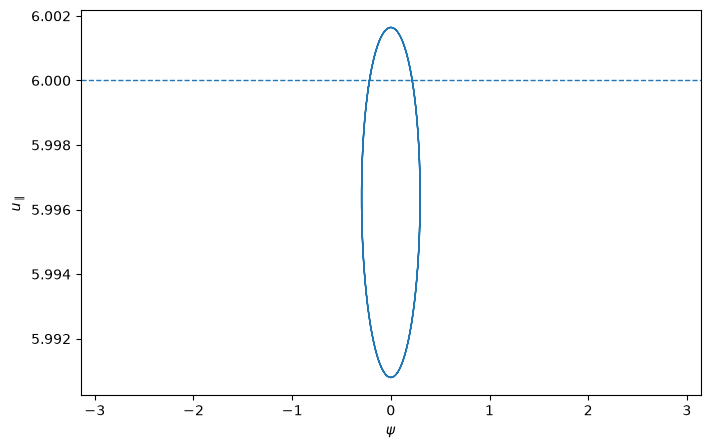

In [27]:
# 先挑一个初始位于 separatrix 内的粒子，画它的 \((\psi,u_\parallel)\) 轨迹。
# inside_separatrix0 大概长这样：[False, False, True, False, True, ...]
# np.where(condition) 会返回所有满足条件的位置。
# 例如：a = np.array([False, True, False, True])。那么，np.where(a) 会得到 (array([1, 3]),)
# 之所以后面还有：[0]，是因为 np.where() 返回的是一个 tuple。
# 所以：np.where(a)[0]，才真正拿到：array([1, 3])
inside_indices = np.where(inside_separatrix0)[0]

print("Number of initially inside particles =", len(inside_indices))
print("First 10 indices =", inside_indices[:10])

# 然后先选第一个：
particle_id = deepest_id

print("particle id =", particle_id)
print("initial u_parallel =", u_parallel0[particle_id])
print("initial u_perp =", u_perp0[particle_id])
print("initial psi =", psi0[particle_id])

# 找见被困的最深的粒子
inside_ratio = (
    np.abs(u_parallel0 - U_RESONANCE)
    / separatrix_half_width0
)

deepest_id = inside_indices[
    np.argmin(inside_ratio[inside_indices])
]

print("deepest particle id =", deepest_id)
print("inside ratio =", inside_ratio[deepest_id])
print("u_parallel0 =", u_parallel0[deepest_id])
print("u_perp0 =", u_perp0[deepest_id])
print("psi0 =", psi0[deepest_id])

# 接着画最简单的 phase-space trajectory。
# 注意，这里和论文不一样，没有用近似，所以共振速度不是严格的6
plt.figure(figsize=(8, 5))
plt.plot(
    psi_wrapped_history[:, particle_id],
    u_parallel_history[:, particle_id],
    linewidth=1.0
)
plt.axhline(
    U_RESONANCE,
    linestyle="--",
    linewidth=1.0
)
plt.xlabel(r"$\psi$")
plt.ylabel(r"$u_\parallel$")
plt.xlim(-np.pi, np.pi)
plt.show()

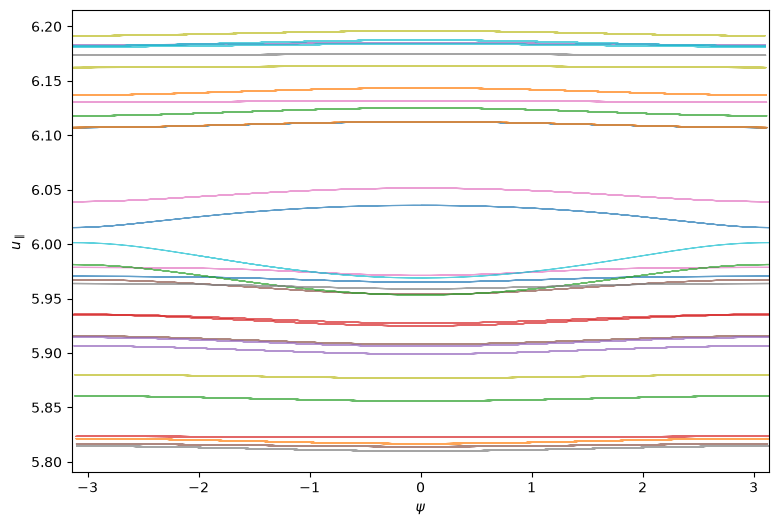

In [28]:
# 我们可以先从 720 个粒子中均匀挑一些出来，例如 30 个
# Select particles directly from simulation data
N_PLOT_PARTICLES = 30

plot_indices = np.linspace(
    0,
    N_PARTICLES - 1,
    N_PLOT_PARTICLES,
    dtype=int
)
plt.figure(figsize=(9, 6))

for particle_id in plot_indices:

    psi_plot = psi_wrapped_history[:, particle_id].copy()
    u_parallel_plot = u_parallel_history[:, particle_id].copy()

    # Remove artificial lines caused by phase wrapping
    phase_jump = np.abs(np.diff(psi_plot)) > np.pi
    jump_indices = np.where(phase_jump)[0] + 1

    psi_plot[jump_indices] = np.nan
    u_parallel_plot[jump_indices] = np.nan

    plt.plot(
        psi_plot,
        u_parallel_plot,
        linewidth=0.8,
        alpha=0.7
    )

plt.xlabel(r"$\psi$")
plt.ylabel(r"$u_\parallel$")

plt.xlim(-np.pi, np.pi)

plt.show()

In [29]:
# Numerical phase-space scan
# 固定垂直速度为一个定值，只改变平行速度的数值。重新用推进器生成一组数据专门用来画图。

U_PERP_PHASE_SCAN = 0.65

N_U_PARALLEL = 41 # 定义41个网格的平行速度
N_PSI = 41 # 定义41个网格的ψ

u_parallel_scan = np.linspace(
    U_PARALLEL_MIN,
    U_PARALLEL_MAX,
    N_U_PARALLEL
)

psi_scan = np.linspace(
    PSI_MIN,
    PSI_MAX,
    N_PSI
)
# 组合成一个二维网格
U_PARALLEL_GRID, PSI_GRID = np.meshgrid(
    u_parallel_scan,
    psi_scan,
    indexing="xy"
)
print(U_PARALLEL_GRID.shape)
print(PSI_GRID.shape)

# Boris pusher 需要的是一维粒子数组，所以再把二维网格展开（1681个数据）
u_parallel_phase0 = U_PARALLEL_GRID.ravel()
psi_phase0 = PSI_GRID.ravel()
# 固定垂直速度：
u_perp_phase0 = np.full(
    u_parallel_phase0.shape,
    U_PERP_PHASE_SCAN
)
print(u_parallel_phase0.shape)
print(psi_phase0.shape)
print(u_perp_phase0.shape)

(41, 41)
(41, 41)
(1681,)
(1681,)
(1681,)


In [30]:
# Initial conditions for phase-space scan

N_PHASE_PARTICLES = len(u_parallel_phase0)

x_phase0 = np.zeros(N_PHASE_PARTICLES)

u_x_phase0 = u_parallel_phase0

u_y_phase0 = (
    u_perp_phase0 * np.sin(psi_phase0)
)

u_z_phase0 = (
    u_perp_phase0 * np.cos(psi_phase0)
)

tau_phase0 = 0.0

u_perp_phase_check = np.sqrt(
    u_y_phase0**2 + u_z_phase0**2
)

print("Number of phase-scan particles =", N_PHASE_PARTICLES)
print("u_perp target =", U_PERP_PHASE_SCAN)
print("first 5 u_perp check =", u_perp_phase_check[:5])

Number of phase-scan particles = 1681
u_perp target = 0.65
first 5 u_perp check = [0.65 0.65 0.65 0.65 0.65]


In [31]:
# 设置这次 phase-space scan 的时间参数
# ==========================================
# Phase-space scan simulation parameters
# ==========================================

DT_PHASE = 0.01
TAU_END_PHASE = 5000.0

N_STEPS_PHASE = int(
    round(TAU_END_PHASE / DT_PHASE)
)

# 这次主要为了画 phase portrait
# 每 100 个 Boris steps 保存一次
SAVE_EVERY_PHASE = 100

N_SAVED_PHASE = (
    N_STEPS_PHASE // SAVE_EVERY_PHASE + 1
)

print("N_PHASE_PARTICLES =", N_PHASE_PARTICLES)
print("DT_PHASE =", DT_PHASE)
print("TAU_END_PHASE =", TAU_END_PHASE)
print("N_STEPS_PHASE =", N_STEPS_PHASE)
print("N_SAVED_PHASE =", N_SAVED_PHASE)

N_PHASE_PARTICLES = 1681
DT_PHASE = 0.01
TAU_END_PHASE = 5000.0
N_STEPS_PHASE = 500000
N_SAVED_PHASE = 5001


In [32]:
# 建立用于推进的状态
# ==========================================
# Current states
# ==========================================

x_phase = x_phase0.copy()

u_x_phase = u_x_phase0.copy()
u_y_phase = u_y_phase0.copy()
u_z_phase = u_z_phase0.copy()

tau_phase = tau_phase0

# 创建保存数组
# ==========================================
# Allocate history arrays
# ==========================================

tau_phase_history = np.empty(
    N_SAVED_PHASE,
    dtype=np.float64
)

u_parallel_phase_history = np.empty(
    (N_SAVED_PHASE, N_PHASE_PARTICLES),
    dtype=np.float64
)

u_perp_phase_history = np.empty(
    (N_SAVED_PHASE, N_PHASE_PARTICLES),
    dtype=np.float64
)

psi_phase_history = np.empty(
    (N_SAVED_PHASE, N_PHASE_PARTICLES),
    dtype=np.float64
)

# 先保存 \(t=0\) 的初始状态
# ==========================================
# Save initial state
# ==========================================

save_index = 0

tau_phase_history[save_index] = tau_phase

# Parallel velocity
u_parallel_phase_history[save_index] = u_x_phase

# Perpendicular velocity
u_perp_phase_history[save_index] = np.sqrt(
    u_y_phase**2 + u_z_phase**2
)

# Particle gyrophase Phi
phi_particle = np.arctan2(
    u_y_phase,
    u_z_phase
)

# Wave magnetic phase Phi_B
phi_B_particle = wave_phase(
    x_phase,
    tau_phase
)

# Relative phase psi = Phi - Phi_B
psi_particle = (
    phi_particle - phi_B_particle
)

# Wrap psi into [-pi, pi)
psi_phase_history[save_index] = (
    psi_particle + np.pi
) % (2.0 * np.pi) - np.pi

save_index += 1

# 正式运行 1681 个 test particles
# ==========================================
# Main phase-space scan
# ==========================================

start_time = time.time()

for step in range(1, N_STEPS_PHASE + 1):

    # One Boris step
    (
        x_phase,
        u_x_phase,
        u_y_phase,
        u_z_phase,
        tau_phase
    ) = boris_push(
        x_phase,
        u_x_phase,
        u_y_phase,
        u_z_phase,
        tau_phase,
        DT_PHASE
    )

    # Save results
    if step % SAVE_EVERY_PHASE == 0:

        tau_phase_history[save_index] = tau_phase

        # Parallel velocity
        u_parallel_phase_history[save_index] = (
            u_x_phase
        )

        # Perpendicular velocity
        u_perp_phase_history[save_index] = np.sqrt(
            u_y_phase**2
            + u_z_phase**2
        )

        # Particle gyrophase Phi
        phi_particle = np.arctan2(
            u_y_phase,
            u_z_phase
        )

        # Wave magnetic phase Phi_B
        phi_B_particle = wave_phase(
            x_phase,
            tau_phase
        )

        # Relative phase psi
        psi_particle = (
            phi_particle
            - phi_B_particle
        )

        # Wrap to [-pi, pi)
        psi_phase_history[save_index] = (
            psi_particle + np.pi
        ) % (2.0 * np.pi) - np.pi

        save_index += 1

    # Progress information
    if step % 50000 == 0:

        elapsed = time.time() - start_time

        print(
            f"step = {step:6d} / {N_STEPS_PHASE}, "
            f"tau = {tau_phase:8.2f}, "
            f"elapsed = {elapsed:.1f} s"
        )


elapsed = time.time() - start_time

print()
print("Phase-space simulation finished.")
print("Final tau =", tau_phase)
print("Saved states =", save_index)
print(f"Total runtime = {elapsed:.2f} s")

# 保存结果
# ==========================================
# Save phase-space scan data
# ==========================================

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

phase_output_file = (
    DATA_DIR / "phase_space_scan.npz"
)

np.savez_compressed(
    phase_output_file,

    tau=tau_phase_history,

    u_parallel=u_parallel_phase_history,
    u_perp=u_perp_phase_history,
    psi=psi_phase_history,

    u_parallel0=u_parallel_phase0,
    u_perp0=u_perp_phase0,
    psi0=psi_phase0,

    W=W,
    K=K,
    BW=BW,

    DT_PHASE=DT_PHASE,
    TAU_END_PHASE=TAU_END_PHASE,
    SAVE_EVERY_PHASE=SAVE_EVERY_PHASE
)

print("Saved to:")
print(phase_output_file)

step =  50000 / 500000, tau =   500.00, elapsed = 7.1 s
step = 100000 / 500000, tau =  1000.00, elapsed = 12.6 s
step = 150000 / 500000, tau =  1500.00, elapsed = 18.0 s
step = 200000 / 500000, tau =  2000.00, elapsed = 23.8 s
step = 250000 / 500000, tau =  2500.00, elapsed = 29.6 s
step = 300000 / 500000, tau =  3000.00, elapsed = 35.2 s
step = 350000 / 500000, tau =  3500.00, elapsed = 40.7 s
step = 400000 / 500000, tau =  4000.00, elapsed = 47.6 s
step = 450000 / 500000, tau =  4500.00, elapsed = 57.7 s
step = 500000 / 500000, tau =  5000.00, elapsed = 64.1 s

Phase-space simulation finished.
Final tau = 5000.000000062718
Saved states = 5001
Total runtime = 64.11 s
Saved to:
/Users/zerek/Desktop/plasma physics/AI_hoshino/notebook_outputs/simulation_particle/data/phase_space_scan.npz


Number of plotted trajectories = 121


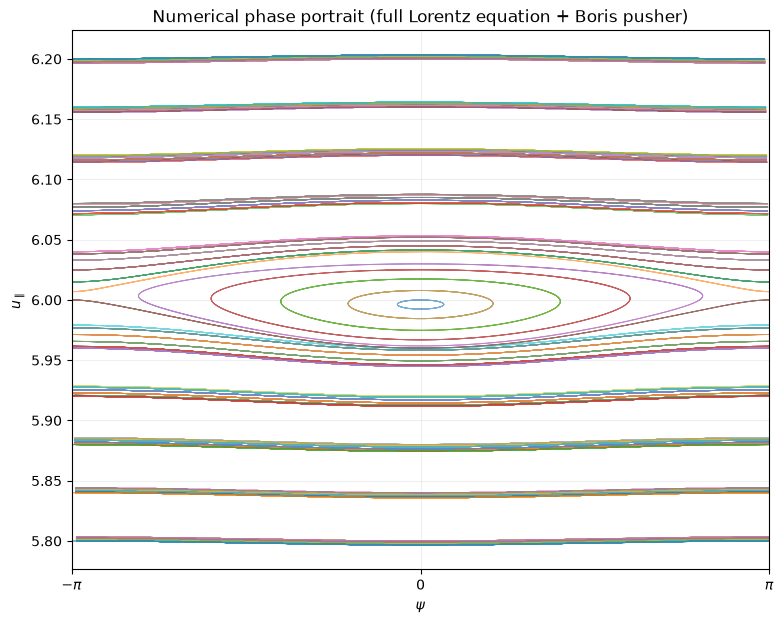

In [33]:
# 每隔 4 个网格点取一个
# ==========================================
# Select numerical trajectories for plotting
# ==========================================

plot_indices = []

for j in range(0, N_PSI, 4):
    for i in range(0, N_U_PARALLEL, 4):

        particle_id = (
            j * N_U_PARALLEL + i
        )

        plot_indices.append(particle_id)

plot_indices = np.array(plot_indices)

print(
    "Number of plotted trajectories =",
    len(plot_indices)
)

# 画图，同时把phase wrapping 导致的假横线处理掉
# ==========================================
# Numerical phase portrait
# ==========================================

plt.figure(figsize=(9, 7))

for particle_id in plot_indices:

    psi_plot = (
        psi_phase_history[:, particle_id].copy()
    )

    u_parallel_plot = (
        u_parallel_phase_history[:, particle_id].copy()
    )

    # Detect artificial jumps at ±pi
    phase_jump = (
        np.abs(np.diff(psi_plot)) > np.pi
    )

    jump_indices = (
        np.where(phase_jump)[0] + 1
    )

    # Break the line at periodic boundaries
    psi_plot[jump_indices] = np.nan
    u_parallel_plot[jump_indices] = np.nan

    plt.plot(
        psi_plot,
        u_parallel_plot,
        linewidth=0.7,
        alpha=0.6
    )


plt.xlabel(r"$\psi$")
plt.ylabel(r"$u_\parallel$")

plt.xlim(
    -np.pi,
    np.pi
)

plt.xticks(
    [-np.pi, 0, np.pi],
    [r"$-\pi$", r"$0$", r"$\pi$"]
)

plt.title(
    "Numerical phase portrait "
    "(full Lorentz equation + Boris pusher)"
)

plt.grid(alpha=0.2)

plt.show()